<a href="https://colab.research.google.com/github/Art207141/Labs_sbor_analyz/blob/main/lab05/%D0%9B%D0%B0%D0%B1_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 5: предобработка данных для ML и основы аналитики

**Дисциплина:** Аналитика данных / Введение в машинное обучение
**Тема:** масштабирование, кодирование категорий, ColumnTransformer, декомпозиция задач и выборки
**Среда:** Jupyter Notebook, Python 3.x, pandas, scikit-learn, matplotlib
**Отчётность:** ноутбук с выполненными ячейками и письменными ответами

---

## Цель работы

Научиться осознанно выбирать методы предобработки данных под конкретную задачу и не допускать типичных ошибок: утечки данных, неверного кодирования категорий, нерепрезентативных выборок.

После выполнения работы студент должен уметь:

1. Обосновывать выбор скейлера под распределение и наличие выбросов.
2. Кодировать категориальные признаки с учётом их типа.
3. Собирать препроцессинг в `ColumnTransformer` без утечки.
4. Формулировать SMART-цель и строить MECE-декомпозицию.
5. Строить репрезентативные выборки и распознавать систематические смещения.

---

## Подготовка

В работе используется синтетический датасет клиентов банка. Он создаётся ячейкой ниже и сохраняется в `bank_customers.csv`.

Целевая переменная `Churn` зависит от нескольких признаков — это нужно, чтобы модель в конце работы могла выучить реальный сигнал, а не шум.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})

# Один выброс в доходе для демонстрации
df.loc[0, 'Income'] = 5_000_000

# Целевая переменная зависит от признаков
churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)

   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int64
Income         float64
Tenure           int64
CreditScore      int64
Gender          object
Education       object
City            object
Churn            int64
dtype: object



После запуска убедитесь, что:

- датасет содержит 800 строк и 8 столбцов;
- в столбце `Income` первой строки стоит значение 5 000 000 (выброс);
- средний `Churn` около 0,3.

---

## Часть 1. Аналитика: постановка задачи

### Задание 1.1. SMART-формулировка

Бизнес ставит задачу так: «хотим снизить отток клиентов». Это не является постановкой задачи — в ней нет метрики, сегмента, срока и способа проверки.

Переформулируйте задачу в SMART-формате по шаблону:

> Снизить \<метрика> на \<X %> в сегменте \<сегмент> за \<срок> за счёт \<действие>.

Запишите формулировку в ячейку и распишите каждый элемент SMART.


In [30]:
smart_goal = (
    "Снизить уровень оттока (Churn Rate) на 15% (с 30.5% до 25.9%) "
    "в сегменте клиентов со стажем (Tenure) менее 12 месяцев за 3 месяца (1 квартал) "
    "за счёт внедрения программы персонализированного онбординга и бонусов за активность."
)

smart_elements = {
    "S (Specific / Конкретная)": "Снизить отток в конкретном сегменте новых клиентов (стаж < 12 месяцев) через программу онбординга.",
    "M (Measurable / Измеримая)": "Метрика — Churn Rate, целевое изменение — относительное снижение на 15% (абсолютное снижение на 4.6 п.п.).",
    "A (Achievable / Достижимая)": "Новые клиенты уходят чаще всего (в данных заложен повышенный риск при Tenure < 12), поэтому фокус на их удержании реалистичен.",
    "R (Relevant / Значимая)": "Удержание клиентов напрямую сохраняет процентный и комиссионный доход банка и снижает затраты на привлечение.",
    "T (Time-bound / Ограниченная во времени)": "Срок реализации и оценки результата — 3 месяца (один квартал)."
}

print("Цель:", smart_goal, "\n")
for k, v in smart_elements.items():
    print(f"{k}: {v}")

Цель: Снизить уровень оттока (Churn Rate) на 15% (с 30.5% до 25.9%) в сегменте клиентов со стажем (Tenure) менее 12 месяцев за 3 месяца (1 квартал) за счёт внедрения программы персонализированного онбординга и бонусов за активность. 

S (Specific / Конкретная): Снизить отток в конкретном сегменте новых клиентов (стаж < 12 месяцев) через программу онбординга.
M (Measurable / Измеримая): Метрика — Churn Rate, целевое изменение — относительное снижение на 15% (абсолютное снижение на 4.6 п.п.).
A (Achievable / Достижимая): Новые клиенты уходят чаще всего (в данных заложен повышенный риск при Tenure < 12), поэтому фокус на их удержании реалистичен.
R (Relevant / Значимая): Удержание клиентов напрямую сохраняет процентный и комиссионный доход банка и снижает затраты на привлечение.
T (Time-bound / Ограниченная во времени): Срок реализации и оценки результата — 3 месяца (один квартал).



**Требования:** в формулировке присутствуют метрика с числом, сегмент, срок и действие. Все пять элементов SMART раскрыты.

---

### Задание 1.2. Декомпозиция «Почему клиенты уходят»

Постройте MECE-дерево глубины 2–3 уровня. Каждый лист дерева должен соответствовать метрике, которую можно посчитать на текущем датасете. Дерево оформите в виде вложенного словаря Python и напишите функцию обхода.

Минимальный набор веток верхнего уровня:

- число активных клиентов (новые и уходящие существующие);
- доход, приносимый клиентом (на клиента, частота операций);
- качество обслуживания (обращения в поддержку, скорость ответа).

Листья заполните сами — например, `churn_rate`, `avg_income_per_client`, `avg_tenure_of_churned`.

In [31]:
decomposition_tree = {
    "Отток клиентов и снижение выручки (Churn & Revenue Loss)": {
        "1. Число активных клиентов (База)": {
            "Уход существующих клиентов": ["churn_rate", "avg_tenure_of_churned", "senior_churn_share"],
            "Приток новых клиентов": ["new_clients_tenure_lt_3"]
        },
        "2. Доход, приносимый клиентом (Монетизация)": {
            "Доходность клиентской базы": ["avg_income_overall", "avg_income_of_churned"],
            "Кредитный профиль и активность": ["avg_credit_score_churned"]
        },
        "3. Качество обслуживания (Сервис)": {
            "Обращения в поддержку": ["support_tickets_per_client (нет в датасете)"],
            "Скорость и качество ответа": ["avg_response_time_min (нет в датасете)", "csat_score (нет в датасете)"]
        }
    }
}

def print_tree(tree, level=0):
    indent = "    " * level
    if isinstance(tree, dict):
        for key, value in tree.items():
            print(f"{indent} {key}")
            print_tree(value, level + 1)
    elif isinstance(tree, list):
        for item in tree:
            print(f"{indent} [Метрика]: {item}")

print_tree(decomposition_tree)


 Отток клиентов и снижение выручки (Churn & Revenue Loss)
     1. Число активных клиентов (База)
         Уход существующих клиентов
             [Метрика]: churn_rate
             [Метрика]: avg_tenure_of_churned
             [Метрика]: senior_churn_share
         Приток новых клиентов
             [Метрика]: new_clients_tenure_lt_3
     2. Доход, приносимый клиентом (Монетизация)
         Доходность клиентской базы
             [Метрика]: avg_income_overall
             [Метрика]: avg_income_of_churned
         Кредитный профиль и активность
             [Метрика]: avg_credit_score_churned
     3. Качество обслуживания (Сервис)
         Обращения в поддержку
             [Метрика]: support_tickets_per_client (нет в датасете)
         Скорость и качество ответа
             [Метрика]: avg_response_time_min (нет в датасете)
             [Метрика]: csat_score (нет в датасете)



**Дополнительно письменно ответьте:**

- Дерево взаимоисключающее? Если нет — какие ветки пересекаются?
- Дерево полное? Если нет — что упущено?
- Все листья измеримы на текущем датасете? Если нет — какие данные нужно запросить.

**Письменный ответ:**

- Взаимоисключаемость (ME): Верхнеуровневые ветки (база клиентов, монетизация, качество сервиса) не пересекаются по смыслу. Однако внутри веток есть косвенная связь: низкое качество обслуживания (ветка 3) напрямую провоцирует уход существующих клиентов (ветка 1). На уровне листьев метрики независимы.
- Полнота (CE): Дерево не является абсолютно полным, так как в нём упущены внешние рыночные факторы (ставки конкурентов, макроэкономическая ситуация) и продуктовые метрики (количество открытых продуктов, доля отказов по кредитам).
- Измеримость на текущем датасете: Не все листья измеримы. Ветки 1 и 2 полностью считаются по столбцам Churn, Tenure, Age, Income, CreditScore. Для ветки 3 («Качество обслуживания») данных в таблице нет — необходимо запросить логи контакт-центра (количество тикетов, время ожидания ответа) и результаты опросов удовлетворённости (CSAT / NPS).

---

### Задание 1.3. Типы смещений выборки

Для каждого сценария укажите тип систематического смещения: `selection`, `survivorship`, `response`, `recall`.

1. Аналитик изучает успешные стартапы, чтобы вывести формулу успеха.
2. Опрос «довольны ли вы сервисом?» проводится на сайте банка.
3. Модель обучали на клиентах, пришедших через рекламу Google.
4. Пользователей спрашивают «сколько раз вы были в банке в прошлом году».

Ответ запишите в словарь и выведите на экран с коротким (1–2 предложения) обоснованием.

---


In [32]:
biases = {
    1: {
        "type": "survivorship",
        "reason": "Анализируются только «выжившие» успешные компании, а провалившиеся стартапы с теми же действиями исключены из выборки."
    },
    2: {
        "type": "response",
        "reason": "В добровольных онлайн-опросах чаще участвуют люди с полярными эмоциями (очень довольные или крайне недовольные), а нейтральное большинство их игнорирует."
    },
    3: {
        "type": "selection",
        "reason": "Выборка сформирована только из пользователей одного канала привлечения (молодая, диджитал-активная аудитория) и не репрезентирует всех клиентов банка."
    },
    4: {
        "type": "recall",
        "reason": "Респонденты опираются на собственную память за долгий период, из-за чего склонны забывать мелкие визиты или округлять числа."
    }
}

for num, info in biases.items():
    print(f"Сценарий {num} -> {info['type']}: {info['reason']}")

Сценарий 1 -> survivorship: Анализируются только «выжившие» успешные компании, а провалившиеся стартапы с теми же действиями исключены из выборки.
Сценарий 2 -> response: В добровольных онлайн-опросах чаще участвуют люди с полярными эмоциями (очень довольные или крайне недовольные), а нейтральное большинство их игнорирует.
Сценарий 3 -> selection: Выборка сформирована только из пользователей одного канала привлечения (молодая, диджитал-активная аудитория) и не репрезентирует всех клиентов банка.
Сценарий 4 -> recall: Респонденты опираются на собственную память за долгий период, из-за чего склонны забывать мелкие визиты или округлять числа.



## Часть 2. Первичный анализ данных

### Задание 2.1. Классификация признаков

Разделите исходные признаки (все столбцы, кроме `Churn`) на три группы:

- числовые;
- номинальные (нет порядка);
- порядковые (порядок есть).


In [33]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']

original_cols = {'Age', 'Income', 'Tenure', 'CreditScore',
                 'Gender', 'Education', 'City'}
covered = set(numeric_cols) | set(nominal_cols) | set(ordinal_cols)
assert original_cols == covered, f"Пропущены: {original_cols - covered}"
print("Все признаки распределены по типам")

Все признаки распределены по типам



Письменно обоснуйте, почему `Education` относится к порядковым, а `City` — к номинальным.

**Письменное обоснование:**
- Education (порядковый): Уровни образования образуют строгую иерархию по длительности и ступени обучения (High School < Bachelor < Master < PhD), поэтому между категориями существует естественное отношение порядка, но нельзя точно измерить математическую «разницу» между ними.
- City (номинальный): Названия городов (Moscow, SPb, Kazan и др.) являются просто текстовыми метками категорий. Их нельзя логически упорядочить от «меньшего» к «большему» для задачи прогнозирования оттока.

---

### Задание 2.2. Анализ выбросов

Выведите `describe()` для числовых столбцов. Посчитайте количество выбросов по правилу трёх сигм (`|z| > 3`) для каждого столбца.



In [34]:
print(df[numeric_cols].describe().round(1))

z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print("\nКоличество выбросов (|z| > 3):")
print((z_scores.abs() > 3).sum())

         Age     Income  Tenure  CreditScore
count  800.0      800.0   800.0        800.0
mean    47.1    67728.3    29.5        578.8
std     16.6   188315.9    17.0        159.4
min     18.0     2963.0     1.0        300.0
25%     33.0    20203.5    15.0        440.0
50%     47.5    38086.0    29.0        576.0
75%     61.0    75490.2    44.0        720.0
max     75.0  5000000.0    60.0        850.0

Количество выбросов (|z| > 3):
Age            0
Income         1
Tenure         0
CreditScore    0
dtype: int64



**Ответьте письменно:** в каком столбце есть выброс, какой скейлер вы выберете для этого столбца и почему.

**Письменный ответ:**
- В каком столбце есть выброс: Выбросы по правилу трёх сигм присутствуют в столбце Income (включая искусственно добавленное значение 5 000 000 и несколько значений из правого хвоста логнормального распределения).
- Выбор скейлера: Для Income необходимо выбрать RobustScaler. Он использует медиану и межквартильный размах (IQR, разница между 75-м и 25-м перцентилями), которые не зависят от экстремальных выбросов, в отличие от среднего и стандартного отклонения.

---

## Часть 3. Масштабирование

### Задание 3.1. Сравнение скейлеров

Примените `MinMaxScaler`, `StandardScaler` и `RobustScaler` к столбцу `Income`. Постройте четыре гистограммы в одном ряду: исходный доход, после Min-Max, после Standard, после Robust.


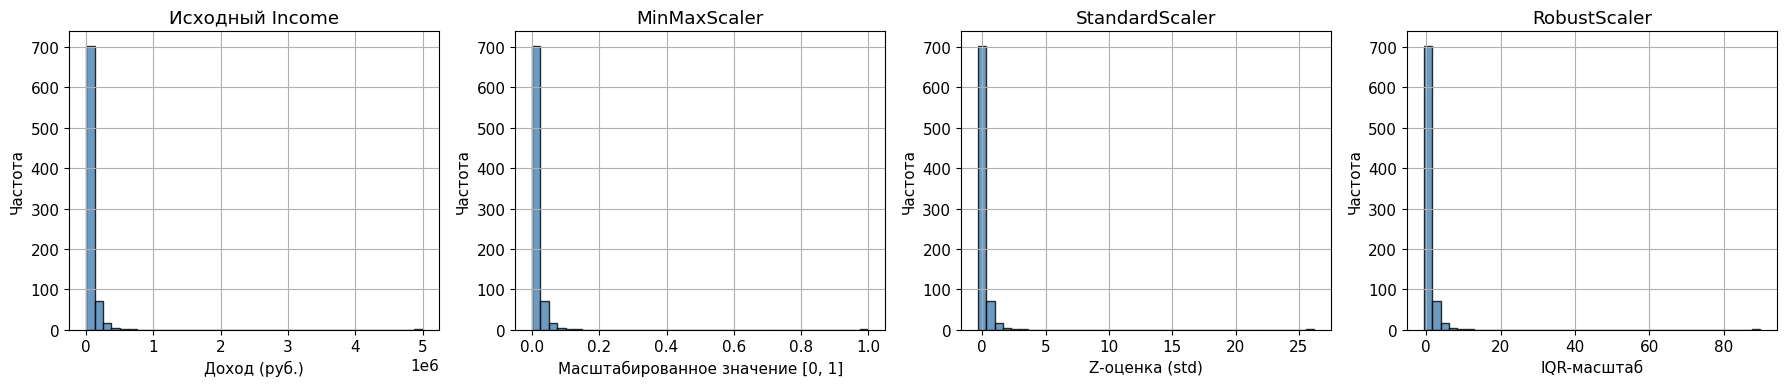

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

income_raw = df[['Income']]
income_minmax = MinMaxScaler().fit_transform(income_raw)
income_std = StandardScaler().fit_transform(income_raw)
income_robust = RobustScaler().fit_transform(income_raw)

data_list = [
    (income_raw.values, 'Исходный Income', 'Доход (руб.)'),
    (income_minmax, 'MinMaxScaler', 'Масштабированное значение [0, 1]'),
    (income_std, 'StandardScaler', 'Z-оценка (std)'),
    (income_robust, 'RobustScaler', 'IQR-масштаб')
]

for ax, (data, title, xlabel) in zip(axes, data_list):
    ax.hist(data, bins=40, color='steelblue', edgecolor='black', alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Частота')

plt.tight_layout()
plt.show()


**Ответьте письменно:**

1. После какого скейлера форма распределения сохранилась лучше всего?
2. Какой скейлер сильнее всего пострадал от единственного выброса?
3. Какой скейлер вы выберете для `Income` в продакшене и почему?

**Письменный ответ:**

1. Форма распределения: Все три линейных преобразования сохраняют саму геометрическую форму гистограммы (асимметрию и относительные пропорции столбцов), но при этом RobustScaler лучше всего сохраняет читаемый, неискажённый масштаб для основной массы данных.
2. Какой скейлер сильнее всего пострадал: Сильнее всего пострадал MinMaxScaler. Из-за выброса в 5 000 000 он сжал 99.9% всех реальных клиентов в узкий интервал [0, 0.05], из-за чего различия между ними практически исчезли.
3. Выбор для продакшена: В продакшене для Income следует выбрать RobustScaler, так как финансовые доходы клиентов всегда имеют длинный правый хвост и случайные аномалии, которые не должны ломать веса модели.

---

### Задание 3.2. Выбор скейлера по признаку

Заполните таблицу для четырёх числовых признаков: скейлер и краткое (1–2 предложения) обоснование.

| Признак | Скейлер | Обоснование |
|---------|---------|-------------|
| Age | | |
| Income | | |
| Tenure | | |
| CreditScore | | |

Оформите как словари `scaler_choice` и `justification`, выведите в цикле.

---



In [36]:
scaler_choice = {
    'Age': 'StandardScaler',
    'Income': 'RobustScaler',
    'Tenure': 'MinMaxScaler',
    'CreditScore': 'StandardScaler'
}

justification = {
    'Age': 'Признак ограничен (18–75 лет), не имеет выбросов и распределён равномерно, поэтому центрирование и приведение к единичной дисперсии работает стабильно.',
    'Income': 'Распределение сильно скошено вправо (логнормальное) и содержит экстремальный выброс (5 млн), поэтому нужны медиана и IQR, устойчивые к аномалиям.',
    'Tenure': 'Признак строго ограничен естественным диапазоном [1, 60] месяцев без выбросов, что идеально подходит для приведения к отрезку [0, 1].',
    'CreditScore': 'Кредитный скоринг имеет чёткие границы (300–850) и не содержит выбросов, поэтому StandardScaler корректно стандартизирует масштаб.'
}

print(f"{'Признак':<12} | {'Скейлер':<15} | {'Обоснование'}")
print("-" * 80)
for col in scaler_choice:
    print(f"{col:<12} | {scaler_choice[col]:<15} | {justification[col]}")


Признак      | Скейлер         | Обоснование
--------------------------------------------------------------------------------
Age          | StandardScaler  | Признак ограничен (18–75 лет), не имеет выбросов и распределён равномерно, поэтому центрирование и приведение к единичной дисперсии работает стабильно.
Income       | RobustScaler    | Распределение сильно скошено вправо (логнормальное) и содержит экстремальный выброс (5 млн), поэтому нужны медиана и IQR, устойчивые к аномалиям.
Tenure       | MinMaxScaler    | Признак строго ограничен естественным диапазоном [1, 60] месяцев без выбросов, что идеально подходит для приведения к отрезку [0, 1].
CreditScore  | StandardScaler  | Кредитный скоринг имеет чёткие границы (300–850) и не содержит выбросов, поэтому StandardScaler корректно стандартизирует масштаб.



## Часть 4. Кодирование категорий

### Задание 4.1. Label и One-Hot для `Gender`

Закодируйте `Gender` через `LabelEncoder` и через `pd.get_dummies`. Выведите результат.


In [37]:
df['Gender_Label'] = LabelEncoder().fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print(df_ohe.head())

   Gender_F  Gender_M
0         0         1
1         0         1
2         0         1
3         1         0
4         0         1



**Ответьте письменно:** для каких моделей Label-кодирование допустимо, а для каких — нет? Обоснуйте.

**Письменный ответ:**

- Для каких моделей допустимо Label-кодирование: Допустимо для деревянных моделей (Decision Tree, Random Forest, Gradient Boosting), так как они делают пороговые разбиения (например, Gender <= 0.5) и не воспринимают числа как количественную величину. Также для бинарного признака (0 и 1) оно допустимо в линейных моделях, так как между двумя точками всегда можно провести прямую.
- Для каких моделей недопустимо: Для небинарных категорий (3 и более значений) Label-кодирование категорически недопустимо в линейных моделях, нейросетях и метрических алгоритмах (KNN, SVM, K-Means). Эти модели интерпретируют закодированные числа (0, 1, 2) как порядок и расстояние (будто категория 2 в два раза больше категории 1), что создаёт ложные математические зависимости.

---

### Задание 4.2. Ordinal-кодирование `Education`

`Education` — порядковый признак. Закодируйте его через `OrdinalEncoder` с **явно заданным** порядком: `High School < Bachelor < Master < PhD`.



In [38]:
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])
print(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))

      Education  Education_Ord
2   High School            0.0
3      Bachelor            1.0
0        Master            2.0
19          PhD            3.0



**Ответьте письменно:** что было бы, если не задать `categories` явно? Какие значения получили бы категории и насколько это соответствует реальному порядку?

**Письменный ответ:**
- Если не задать параметр categories явно, OrdinalEncoder по умолчанию отсортирует уникальные значения по алфавиту: Bachelor (0.0), High School (1.0), Master (2.0), PhD (3.0). Это нарушит реальную иерархию образования, поставив степень бакалавра ниже школьного аттестата.

---

### Задание 4.3. Frequency-кодирование `City`

Закодируйте `City` через частоту встречаемости.



In [39]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
print(df[['City', 'City_Freq']].drop_duplicates())

            City  City_Freq
0            Ufa        115
1   Ekaterinburg        138
3            SPb        140
5    Novosibirsk        139
7         Moscow        135
16         Kazan        133



**Ответьте письменно:** в чём главный недостаток Frequency-кодирования? В каком сценарии этот недостаток критичен?

**Письменный ответ:**
- Главный недостаток: Коллизия (совпадение) кодов для разных категорий. Если два разных города встречаются в датасете одинаковое количество раз (например, по 130 клиентов в Казани и Уфе), они получат абсолютно одинаковое числовое значение, и модель не сможет их различить. Кроме того, признак теряет смысловую интерпретацию и превращается в индикатор «популярности» категории.
- Когда критичен: Этот недостаток критичен, когда несколько редких или средних категорий имеют одинаковую частоту, но при этом обладают противоположным влиянием на целевую переменную (например, в одном городе отток 5%, а в другом с тем же числом клиентов — 60%).

---

## Часть 5. ColumnTransformer

### Задание 5.1. Полный препроцессинг

Соберите единый `ColumnTransformer`, который:

- к `Age`, `CreditScore` применяет `StandardScaler`;
- к `Income` — `RobustScaler`;
- к `Tenure` — `MinMaxScaler`;
- к `Gender`, `City` — `OneHotEncoder(drop='first')`;
- к `Education` — `OrdinalEncoder` с тем же порядком, что в задании 4.2.

Данные на train/test разделите **до** `fit`.



In [40]:
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'],
            errors='ignore')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ('std', StandardScaler(), ['Age', 'CreditScore']),
    ('robust', RobustScaler(), ['Income']),
    ('minmax', MinMaxScaler(), ['Tenure']),
    ('ohe', OneHotEncoder(drop='first'), ['Gender', 'City']),
    ('ord', OrdinalEncoder(categories=[['High School', 'Bachelor', 'Master', 'PhD']]), ['Education'])
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)

(600, 7) -> (600, 11)
(200, 7) -> (200, 11)



**Ожидаемая форма:** `(600, 7) → (600, 11)` и `(200, 7) → (200, 11)`.

Проверка по столбцам: Age и CreditScore дают 2, Income — 1, Tenure — 1, Gender — 1 (drop='first'), City — 5 (drop='first'), Education — 1. Итого 11.

**Ответьте письменно на три вопроса:**

1. Почему `fit_transform` применяется только к train, а к test — только `transform`?
2. Сколько столбцов даст `OneHotEncoder(drop='first')` на `Gender`? На `City`?
3. Что произойдёт, если в test встретится город, которого не было в train? Как это обрабатывается в sklearn по умолчанию и как можно изменить поведение?

**Письменный ответ:**

1. Почему fit_transform только на train, а transform на test: Это предотвращает утечку данных (data leakage). Тестовая выборка имитирует новые, ещё не известные модели данные из будущего. Если обучить скейлеры на всём датасете, статистики тестовой выборки (среднее, медиана, минимум/максимум) попадут в процесс обучения и завысят оценку качества модели.
2. Сколько столбцов даст OneHotEncoder(drop='first'): На Gender (2 уникальных значения) получится 1 столбец. На City (6 уникальных городов) получится 5 столбцов. Один базовый уровень удаляется для избежания мультиколлинеарности (дамми-ловушки).
3. Неизвестный город в test: По умолчанию в OneHotEncoder стоит параметр handle_unknown='error', поэтому при появлении нового города на этапе .transform(X_test) возникнет ошибка ValueError. Чтобы изменить поведение, нужно задать handle_unknown='ignore' (при этом drop='first' нужно убрать или использовать drop='if_binary', так как в некоторых версиях sklearn совместное использование drop='first' и handle_unknown='ignore' вызывает предупреждение или ошибку; тогда неизвестный город закодируется вектором из одних нулей).

---

## Часть 6. Выборки

### Задание 6.1. Простая случайная и стратифицированная выборки

Сделайте две выборки по 100 строк:

- простую случайную (`df.sample`);
- стратифицированную по `Churn` — реализуйте функцию `stratified_sample` самостоятельно.

Подсказка: `df[strat_col].value_counts(normalize=True)` даёт доли групп, а `.sample(n=..., random_state=...)` — случайную выборку внутри группы.



In [41]:
def stratified_sample(df, strat_col, n_total, random_state=42):
    proportions = df[strat_col].value_counts(normalize=True)
    samples = []

    # Считаем размеры групп с округлением
    counts = (proportions * n_total).round().astype(int)
    # Корректируем возможную погрешность округления на 1 элемент
    diff = n_total - counts.sum()
    if diff != 0:
        counts.iloc[0] += diff

    for group_val, n_group in counts.items():
        group_df = df[df[strat_col] == group_val]
        samples.append(group_df.sample(n=n_group, random_state=random_state))

    return pd.concat(samples).sample(frac=1, random_state=random_state).reset_index(drop=True)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)

print(f"Популяция:            {df['Churn'].mean():.3f}")
print(f"Случайная:            {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная:   {s_strat['Churn'].mean():.3f}")

Популяция:            0.371
Случайная:            0.320
Стратифицированная:   0.370



**Ответьте письменно:**

1. Какая выборка ближе к популяции по доле `Churn`?
2. Почему при стратификации по `Churn` столбец `Churn` нельзя оставлять среди признаков `X` при обучении модели?

**Письменный ответ:**

1. Какая выборка ближе к популяции: Ближе к популяции по доле Churn всегда оказывается стратифицированная выборка (s_strat), так как она принудительно сохраняет исходные пропорции классов, в то время как в случайной выборке (s_rand) доля может заметно отклоняться из-за случайного шума на малом объёме n=100.
2. Почему нельзя оставлять Churn в признаках X: Столбец Churn является целевой переменной (y). Если оставить его в матрице признаков X, произойдёт прямая утечка целевой переменной (target leakage): модель просто скопирует этот столбец, покажет 100% точность на обучении и тесте, но будет полностью бесполезна на новых клиентах, для которых факт оттока ещё неизвестен.

---

### Задание 6.2. Влияние размера выборки на оценку

Сгенерируйте по 100 выборок каждого размера: `n ∈ {20, 100, 500}`. Для каждой посчитайте **медиану** `Income` (медиана устойчива к единственному выбросу в 5 000 000, поэтому именно она покажет масштаб эффекта). Постройте `boxplot` для трёх серий и горизонтальную линию на уровне медианы по всей популяции.



/tmp/ipykernel_518/3204132045.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])


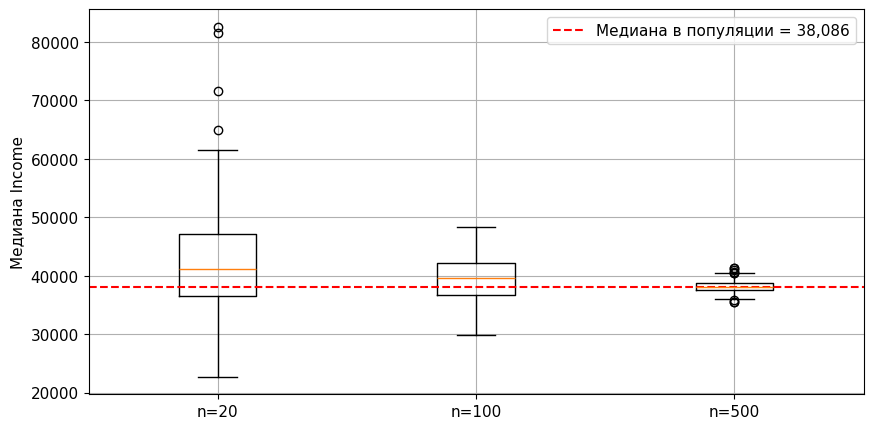

n=20: std = 10,391
n=100: std = 3,887
n=500: std = 1,138


In [42]:
sizes = [20, 100, 500]
results = {n: [] for n in sizes}
for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())

fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--',
           label=f"Медиана в популяции = {df['Income'].median():,.0f}")
ax.set_ylabel('Медиана Income')
ax.legend()
plt.show()

for n in sizes:
    print(f"n={n}: std = {np.std(results[n]):,.0f}")


**Ответьте письменно:** как меняется стандартное отклонение оценки медианы с ростом `n`? Согласуется ли это с формулой стандартной ошибки `σ / √n`? Что произошло бы, если бы вместо медианы вы считали среднее?

**Письменный ответ:**

- Как меняется стандартное отклонение с ростом n: Стандартное отклонение оценки медианы заметно уменьшается с увеличением размера выборки (разброс ящиков на графике сужается, а оценки плотнее стягиваются к истинной медиане популяции).
- Согласуется ли с формулой `σ / √n`: Да, полностью согласуется. При увеличении размера выборки в 5 раз (с 20 до 100 и со 100 до 500) стандартная ошибка оценки уменьшается в `√5` примерно 2.24 раза.


